In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:

import requests

accession = "ERR4387389"

url = "https://www.ebi.ac.uk/ena/portal/api/filereport"

response = requests.get(
    url,
    params={
        "accession": accession,
        "result": "read_run",
        "fields": "run_accession,fastq_ftp",
        "format": "json"
    },
    timeout=30
)

response.raise_for_status()
metadata = response.json()

print(metadata)


[{'run_accession': 'ERR4387389', 'fastq_ftp': 'ftp.sra.ebi.ac.uk/vol1/fastq/ERR438/009/ERR4387389/ERR4387389_1.fastq.gz;ftp.sra.ebi.ac.uk/vol1/fastq/ERR438/009/ERR4387389/ERR4387389_2.fastq.gz'}]


In [3]:

import requests
import gzip
import io

# Get the first FASTQ file URL
fastq_path = metadata[0]["fastq_ftp"].split(";")[0]
fastq_url = "https://" + fastq_path

# Request a small portion of the compressed file
response = requests.get(
    fastq_url,
    headers={"Range": "bytes=0-999999"},
    timeout=60
)

response.raise_for_status()

print("HTTP status:", response.status_code)
print("Downloaded bytes:", len(response.content))


HTTP status: 206
Downloaded bytes: 1000000


In [4]:

import gzip
import io

# Open the downloaded compressed data
with gzip.GzipFile(fileobj=io.BytesIO(response.content)) as fastq:
    # Read the first four lines
    header = fastq.readline().decode().strip()
    sequence = fastq.readline().decode().strip()
    separator = fastq.readline().decode().strip()
    quality = fastq.readline().decode().strip()

print("Read ID:", header)
print("DNA sequence:", sequence)
print("Separator:", separator)
print("Quality string:", quality)

print("Sequence length:", len(sequence))
print("Quality length:", len(quality))


Read ID: @ERR4387389.1 M01548:314:000000000-J6D7T:1:2106:9406:1961/1
DNA sequence: TCTAAAAATTATTCGGTAGTTGTACAACAATGAGTCAGCTGGCCCAGCCTTTGAAGAATTCCTTCAACTATTGGGAGAGCGAGTTCGGCTCAAAGGATTTGAGAAGTATCGAGCACAGCTTGATACCAAAACTGACTCCACAGATCGGAAGAGCACACGTCTGAACTCCAGTCACCGCTCATTATCTCGTATGCCGTCTTCTGCTTTTAAAAAAAAATTTTCTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTCTTTTTTTTTTTTTTTTTTTTTTCTTCTTTT
Separator: +
Quality string: ABC9---6EF9FFF9-F8,EF,E9C9<E,8E,,,CC9,CF8,@CC7,CCFGG99C,,,CFCDFGE99CF8FF,,,,6,,C:++@FE,+@CB9,,,,,CFF,9,,6,C<FF,,,B+C<,CFE8,C,B<,,,<=F,,????8A8,,A?+++++,,:,A8E+EDF+<,EDFE8,D=9AB+>>>7DDA@,@=,@7F,37+8>DECE,>@D,,,,,,,****,,,2,,,,,,***********/****/****/***/****/**/****1**)/*+***+)))*))))))./))))))/**/***
Sequence length: 301
Quality length: 301


First 10 quality scores: [32 33 34 24 12 12 12 21 36 37]
Last 10 quality scores: [ 8  8  8 14  9  9 14  9  9  9]
Average Phred score: 19.96
Minimum Phred score: 8
Maximum Phred score: 38


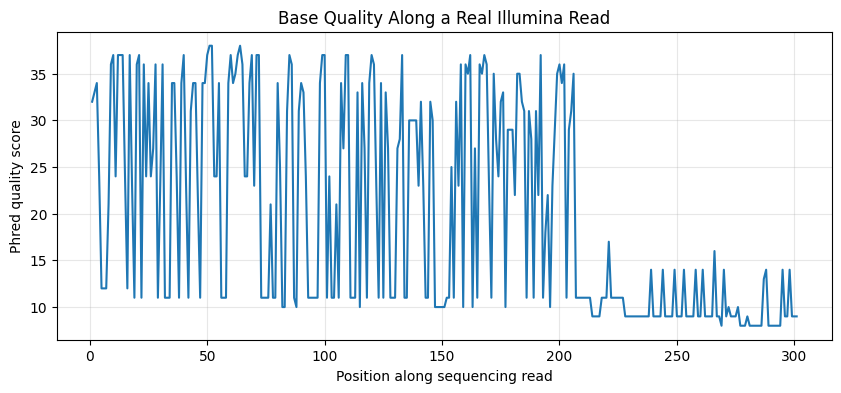

In [5]:

import numpy as np
import matplotlib.pyplot as plt

# Convert FASTQ characters into Phred scores
phred_scores = np.array([ord(char) - 33 for char in quality])

print("First 10 quality scores:", phred_scores[:10])
print("Last 10 quality scores:", phred_scores[-10:])

print(f"Average Phred score: {phred_scores.mean():.2f}")
print(f"Minimum Phred score: {phred_scores.min()}")
print(f"Maximum Phred score: {phred_scores.max()}")

plt.figure(figsize=(10, 4))
plt.plot(range(1, len(phred_scores) + 1), phred_scores)

plt.xlabel("Position along sequencing read")
plt.ylabel("Phred quality score")
plt.title("Base Quality Along a Real Illumina Read")
plt.grid(alpha=0.3)
plt.show()


In [6]:

import gzip
import io
import numpy as np

quality_matrix = []

with gzip.GzipFile(fileobj=io.BytesIO(response.content)) as fastq:
    for i in range(1000):
        try:
            header = fastq.readline()
            sequence = fastq.readline()
            separator = fastq.readline()
            quality_line = fastq.readline()

            if not all([header, sequence, separator, quality_line]):
                break

            scores = [ord(char) - 33 for char in quality_line.decode().strip()]
            quality_matrix.append(scores)

        except (EOFError, OSError):
            break

print(f"Reads collected: {len(quality_matrix)}")
print(f"First read length: {len(quality_matrix[0])}")


Reads collected: 1000
First read length: 301


In [7]:

quality_array = np.array(quality_matrix)

print("Matrix shape:", quality_array.shape)


Matrix shape: (1000, 301)


In [9]:

# Average across reads for each nucleotide position
mean_quality = quality_array.mean(axis=0)

print(f"Position 1: Q{mean_quality[0]:.2f}")
print(f"Position 100: Q{mean_quality[99]:.2f}")
print(f"Position 200: Q{mean_quality[199]:.2f}")
print(f"Position 301: Q{mean_quality[300]:.2f}")


Position 1: Q33.61
Position 100: Q36.95
Position 200: Q30.18
Position 301: Q14.00


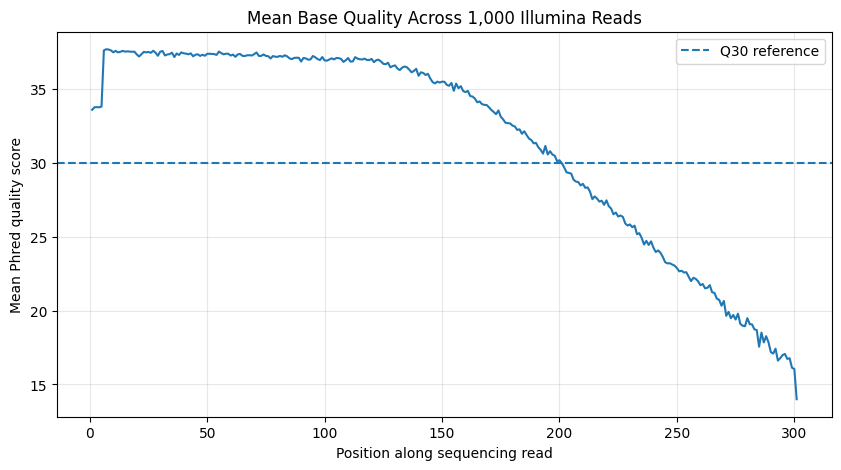

In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(mean_quality) + 1),
    mean_quality
)

plt.axhline(30, linestyle="--", label="Q30 reference")

plt.xlabel("Position along sequencing read")
plt.ylabel("Mean Phred quality score")
plt.title("Mean Base Quality Across 1,000 Illumina Reads")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


In [11]:

# Convert every Phred score into an error probability
error_probabilities = 10 ** (-quality_array / 10)

# Average estimated error probability at each position
mean_error_probability = error_probabilities.mean(axis=0)

for position in [1, 100, 200, 301]:
    q = mean_quality[position - 1]
    error = mean_error_probability[position - 1]

    print(
        f"Position {position}: "
        f"Mean Q = {q:.2f}, "
        f"Mean estimated error = {error:.2%}"
    )


Position 1: Mean Q = 33.61, Mean estimated error = 0.12%
Position 100: Mean Q = 36.95, Mean estimated error = 0.13%
Position 200: Mean Q = 30.18, Mean estimated error = 1.93%
Position 301: Mean Q = 14.00, Mean estimated error = 8.39%


In [13]:

for position in [1, 100, 150, 200, 301]:
    scores = quality_array[:, position - 1]

    percent_q20 = np.mean(scores >= 20) * 100
    percent_q30 = np.mean(scores >= 30) * 100

    print(
        f"Position {position}: "
        f"Q20+ = {percent_q20:.1f}% | "
        f"Q30+ = {percent_q30:.1f}%"
    )


Position 1: Q20+ = 98.8% | Q30+ = 97.7%
Position 100: Q20+ = 98.6% | Q30+ = 96.0%
Position 150: Q20+ = 94.3% | Q30+ = 89.8%
Position 200: Q20+ = 75.5% | Q30+ = 68.4%
Position 301: Q20+ = 18.8% | Q30+ = 6.8%


In [14]:

for cutoff in [150, 200, 301]:
    trimmed = quality_array[:, :cutoff]

    q30_fraction = np.mean(trimmed >= 30)
    mean_q = np.mean(trimmed)

    print(
        f"Cutoff: {cutoff} bases | "
        f"Mean Q: {mean_q:.2f} | "
        f"Q30+: {q30_fraction:.2%}"
    )


Cutoff: 150 bases | Mean Q: 36.96 | Q30+: 96.67%
Cutoff: 200 bases | Mean Q: 35.97 | Q30+: 92.30%
Cutoff: 301 bases | Mean Q: 31.57 | Q30+: 74.54%


In [15]:

for cutoff in [150, 200, 301]:
    # Each base's estimated error probability
    retained_errors = error_probabilities[:, :cutoff]

    # Expected base-call errors per read
    expected_errors = retained_errors.sum(axis=1)

    print(
        f"{cutoff} bases | "
        f"Mean expected errors/read: {expected_errors.mean():.3f}"
    )


150 bases | Mean expected errors/read: 0.197
200 bases | Mean expected errors/read: 0.768
301 bases | Mean expected errors/read: 5.268


In [18]:

# Maximum acceptable expected errors per read
error_budget = 1.0

# Mean estimated error probability at each base position
mean_errors_by_position = error_probabilities.mean(axis=0)

# Cumulative expected errors as we retain more bases
cumulative_errors = np.cumsum(mean_errors_by_position)

# Positions that remain within our error budget
valid_positions = np.where(cumulative_errors <= error_budget)[0]

if len(valid_positions) > 0:
    cutoff = valid_positions[-1] + 1
    print(f"Error budget: {error_budget}")
    print(f"Recommended cutoff: {cutoff} bases")
    print(f"Expected errors/read: {cumulative_errors[cutoff - 1]:.3f}")
else:
    print("Even the first base exceeds the error budget.")


Error budget: 1.0
Recommended cutoff: 210 bases
Expected errors/read: 0.988


In [19]:

# Look at the first read
read_errors = error_probabilities[0]

# Calculate its cumulative expected errors
cumulative = np.cumsum(read_errors)

# Find the longest prefix within our error budget
valid = np.where(cumulative <= 1.0)[0]

cutoff = valid[-1] + 1 if len(valid) > 0 else 0

print(f"Read 1 adaptive cutoff: {cutoff} bases")
print(f"Dataset-wide fixed cutoff: 210 bases")


Read 1 adaptive cutoff: 46 bases
Dataset-wide fixed cutoff: 210 bases


In [22]:

import numpy as np

error_budget = 1.0

# Each row represents one read
cumulative_errors = np.cumsum(
    error_probabilities,
    axis=1
)

# Count how many positions satisfy the error budget
adaptive_cutoffs = np.sum(
    cumulative_errors <= error_budget,
    axis=1
)

print(f"Minimum cutoff: {adaptive_cutoffs.min()}")
print(f"Median cutoff: {np.median(adaptive_cutoffs):.0f}")
print(f"Mean cutoff: {adaptive_cutoffs.mean():.1f}")
print(f"Maximum cutoff: {adaptive_cutoffs.max()}")
print(f"Reads shorter than 150 bases: {np.mean(adaptive_cutoffs < 150):.1%}")
print(f"Reads longer than 250 bases: {np.mean(adaptive_cutoffs > 250):.1%}")

Minimum cutoff: 25
Median cutoff: 241
Mean cutoff: 237.8
Maximum cutoff: 301
Reads shorter than 150 bases: 5.7%
Reads longer than 250 bases: 45.2%


In [23]:

for min_length in [50, 100, 150, 200]:
    passing = adaptive_cutoffs >= min_length

    n_pass = np.sum(passing)
    retention = np.mean(passing)

    print(
        f"Minimum length: {min_length} bases | "
        f"Reads retained: {n_pass} | "
        f"Retention: {retention:.1%}"
    )


Minimum length: 50 bases | Reads retained: 996 | Retention: 99.6%
Minimum length: 100 bases | Reads retained: 983 | Retention: 98.3%
Minimum length: 150 bases | Reads retained: 943 | Retention: 94.3%
Minimum length: 200 bases | Reads retained: 738 | Retention: 73.8%


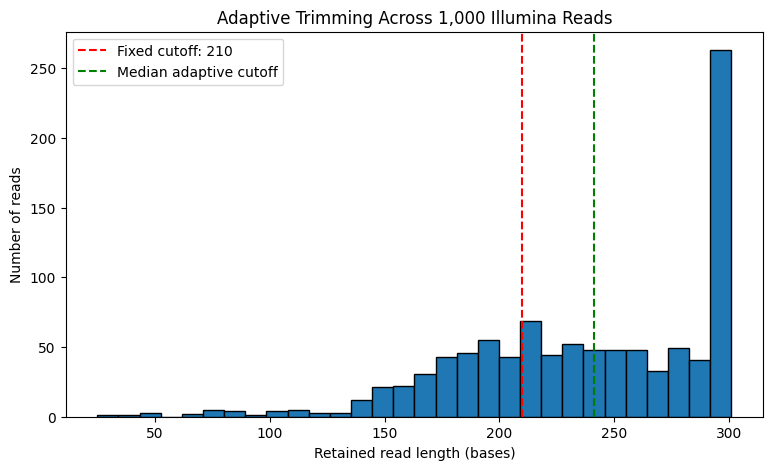

In [24]:

plt.figure(figsize=(9, 5))

plt.hist(adaptive_cutoffs, bins=30, edgecolor="black")

plt.axvline(210, linestyle="--", color="red",
            label="Fixed cutoff: 210")

plt.axvline(np.median(adaptive_cutoffs),
            linestyle="--", color="green",
            label="Median adaptive cutoff")

plt.xlabel("Retained read length (bases)")
plt.ylabel("Number of reads")
plt.title("Adaptive Trimming Across 1,000 Illumina Reads")
plt.legend()
plt.show()


In [25]:

min_length = 150

passing = adaptive_cutoffs >= min_length

total_original_bases = quality_array.size
total_retained_bases = adaptive_cutoffs[passing].sum()

print(f"Original bases: {total_original_bases:,}")
print(f"Retained bases: {total_retained_bases:,}")
print(f"Base retention: {total_retained_bases / total_original_bases:.1%}")
print(f"Mean length of surviving reads: {adaptive_cutoffs[passing].mean():.1f}")


Original bases: 301,000
Retained bases: 231,361
Base retention: 76.9%
Mean length of surviving reads: 245.3


In [26]:

original_errors = error_probabilities.sum()

retained_errors = 0

for i, cutoff in enumerate(adaptive_cutoffs):
    if cutoff >= 150:
        retained_errors += error_probabilities[i, :cutoff].sum()

error_reduction = (1 - retained_errors / original_errors) * 100

print(f"Original expected errors: {original_errors:.1f}")
print(f"Retained expected errors: {retained_errors:.1f}")
print(f"Expected error reduction: {error_reduction:.1f}%")


Original expected errors: 5267.6
Retained expected errors: 755.9
Expected error reduction: 85.7%


In [32]:
cutoff = 150

trimmed_quality = quality_array[:, :cutoff]
total_bases = trimmed_quality.size

# Select the first 150 bases from error_probabilities
trimmed_errors = error_probabilities[:, :cutoff]

# Sum the values in trimmed_errors
total_errors = trimmed_errors.sum()

print("Retained bases:", total_bases)
print("Expected errors:", total_errors)

Retained bases: 150000
Expected errors: 196.55648015939235


In [39]:
cutoff = 210

trimmed_quality = quality_array[:, :cutoff]
total_bases = trimmed_quality.size

# Select the first 210 bases from error_probabilities
trimmed_errors = error_probabilities[:, :cutoff]

# Sum the values in trimmed_errors
total_errors = trimmed_errors.sum()

mean_error_rate = (total_errors / total_bases) *100
errors_per_read = total_errors / quality_array.shape[0]

print("Retained bases:", total_bases)
print("Expected errors:", total_errors)
print(f"Mean error rate: {mean_error_rate:.2f}%")
print(f"Errors per read: {errors_per_read:.2f}")


Retained bases: 210000
Expected errors: 988.4146587336619
Mean error rate: 0.47%
Errors per read: 0.99%


In [45]:
fixed_errors = 988.4147
adaptive_errors = 755.9

# Calculate percentage reduction
error_reduction = ((fixed_errors - adaptive_errors) / fixed_errors) * 100

print(f"Error reduction: {error_reduction:.2f}%")

fixed_trimming = 210000
adaptive_trimming = 231361

bases_saved = ((adaptive_trimming - fixed_trimming) / fixed_trimming) * 100

print(f"Additional bases retained: {bases_saved:.2f}%")

Error reduction: 23.52%
Additional bases retained: 10.17%


In [58]:
def adaptive_trim(phred_scores, error_budget, min_length):

    error_probabilities = 10 ** (-phred_scores / 10)

    cumulative_errors = np.cumsum(error_probabilities)

    valid_positions = np.where(cumulative_errors <= error_budget)[0]

    if len(valid_positions) == 0:
        cutoff = 0
    else:
        cutoff = valid_positions[-1] + 1
        
    passed = cutoff >= min_length

    return (cutoff, passed) 

    # Find the longest cutoff within the error budget

    # Check whether cutoff meets min_length

    # Return cutoff and pass/fail status

In [51]:
result = adaptive_trim(quality_array[99], 1.0, 150)

print(result)

(np.True_, np.int64(233))


In [53]:
test_read = np.full(200, 40)

result = adaptive_trim(test_read, 1.0, 150)

print(result)

(np.True_, np.int64(200))


In [54]:
low_quality_read = np.full(200, 10)

# Call adaptive_trim() here
result = adaptive_trim(low_quality_read, 1.0, 150)

print(result)
# Print the result

(np.False_, np.int64(10))


In [55]:
your_array = np.full(150, 30)
result = adaptive_trim(your_array, 1.0, 150)
print(result)

(np.True_, np.int64(150))


In [67]:
def test_adaptive_trim_high_quality():
    phred_scores = np.full(200, 40)

    cutoff, passed = adaptive_trim(phred_scores, 1.0, 150)
    assert cutoff == 200
    assert passed 

test_adaptive_trim_high_quality()

In [76]:
def test_adaptive_trim_low_quality():
    phred_scores = np.full(200, 10)

    # Call adaptive_trim()
    cutoff, passed = adaptive_trim(phred_scores, 1.0, 150)
    assert cutoff == 10
    assert passed == False

test_adaptive_trim_low_quality()
test_adaptive_trim_high_quality()
    # Assert cutoff is 10

    # Assert passed is False
print("Both tests passed!")

Both tests passed!


In [79]:
def test_adaptive_trim_150_quality():
    phred_scores = np.full(150, 30)

    # Call adaptive_trim()
    cutoff, passed = adaptive_trim(phred_scores, 1.0, 150)
    assert cutoff == 150
    assert passed

test_adaptive_trim_low_quality()
test_adaptive_trim_high_quality()
test_adaptive_trim_150_quality()
    
print("All tests passed!")

All tests passed!
